# Classificação do perfil de investimento

MLP própria em PyTorch para `investmentPolicy`. Métrica principal: F1 macro. Critério: pelo menos 15% acima do melhor baseline no teste.

## 0. Dados, pipeline e separação

Os JSONs são lidos diretamente. A construção do dataset, o pré-processamento,
os modelos e o loop de treino estão definidos nas células abaixo. O
pré-processamento é ajustado somente no treino.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EDA_DIR = Path('../eda')
DATA_DIR = EDA_DIR / 'Dados'


### Construção do dataset


In [2]:
"""Constrói o dataset analítico da classificação diretamente dos JSONs do EDA."""

import json

from json import JSONDecoder

from pathlib import Path

import numpy as np

import pandas as pd

CLASSES = {"Conservadora", "Moderada", "Sofisticada"}

BUCKETS = {
    "stocks": "pct_stocks",
    "fixedIncome": "pct_fixed_income",
    "repo": "pct_repo",
    "investimentFund": "pct_investment_fund",
    "balance": "pct_cash",
    "options": "pct_options",
    "treasure": "pct_treasure",
    "future": "pct_future",
    "privatePension": "pct_private_pension",
    "term": "pct_term",
    "coe": "pct_coe",
    "realEstate": "pct_real_estate",
    "structruedProduct": "pct_structured_product",
}

def stream_json_array(path, chunk_size=1024 * 1024):
    """Lê a wallet, que é uma lista JSON grande, sem carregar tudo de uma vez."""
    decoder = JSONDecoder()
    with open(path, encoding="utf-8") as file:
        buffer = ""
        started = False
        finished = False

        while True:
            if not finished and len(buffer) < chunk_size:
                chunk = file.read(chunk_size)
                if chunk:
                    buffer += chunk
                else:
                    finished = True

            buffer = buffer.lstrip()
            if not started:
                if not buffer:
                    if finished:
                        return
                    continue
                if buffer[0] != "[":
                    raise ValueError("A wallet deve ter uma lista no nível superior.")
                buffer = buffer[1:]
                started = True
                continue

            if buffer.startswith(","):
                buffer = buffer[1:].lstrip()
            if buffer.startswith("]"):
                return
            if not buffer:
                if finished:
                    return
                continue

            try:
                item, end = decoder.raw_decode(buffer)
            except ValueError:
                if finished:
                    raise
                buffer += file.read(chunk_size)
                continue

            buffer = buffer[end:]
            yield item

def bucket_percent(bucket):
    if not isinstance(bucket, dict):
        return 0.0
    value = bucket.get("percent", bucket.get("percentDetail"))
    try:
        return float(value) if value is not None else 0.0
    except (TypeError, ValueError):
        return 0.0

def load_wallet(path):
    rows = []
    for item in stream_json_array(path):
        response = item.get("response") or {}
        output = response.get("output") or {}
        success = bool(response.get("success", False))
        row = {
            "accountCode": str(item.get("client")),
            "wallet_ok": success,
            "wallet_updated_at": output.get("updatedAt"),
        }
        values = []
        for source, column in BUCKETS.items():
            value = bucket_percent(output.get(source)) if success else np.nan
            row[column] = value
            values.append(value)
        row["num_active_buckets"] = int(sum(value > 0 for value in values)) if success else np.nan
        row["max_bucket_pct"] = max(values) if success else np.nan
        row["pct_sum_selected"] = sum(values) if success else np.nan
        row["empty_wallet"] = bool(all(value == 0 for value in values)) if success else False
        rows.append(row)
    return pd.DataFrame(rows)

def build_dataset(data_dir):
    data_dir = Path(data_dir)
    wallet = load_wallet(data_dir / "clientes_wallet_distribution.json")

    with open(data_dir / "clientes_investment_policy.json", encoding="utf-8") as file:
        policy_json = json.load(file)
    policy = pd.DataFrame([
        {
            "accountCode": str(account_code),
            "investmentPolicy": ((obj or {}).get("output") or {}).get("adherence", {}).get("investmentPolicy"),
        }
        for account_code, obj in policy_json.items()
    ])
    policy = policy[policy["investmentPolicy"].isin(CLASSES)].drop_duplicates("accountCode")

    with open(data_dir / "account.json", encoding="utf-8") as file:
        account = pd.DataFrame(json.load(file).get("data", []))
    account["accountCode"] = account["accountCode"].astype(str)
    if "currentRegisterIndicator" in account:
        current = account["currentRegisterIndicator"] == 1
        if current.any():
            account = account[current]
    account = account.drop_duplicates("accountCode", keep="last")

    result = (
        wallet[wallet["wallet_ok"]]
        .merge(policy, on="accountCode", how="inner")
        .merge(account[["accountCode", "personType"]], on="accountCode", how="left")
    )
    return result


### Pré-processamento


In [3]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(
    numeric_features,
    categorical_features,
):
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            ),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_pipeline,
                numeric_features,
            ),
            (
                "cat",
                categorical_pipeline,
                categorical_features,
            ),
        ]
    )

    return preprocessor


### Modelos e treinamento desta versão


In [4]:
"""Funções da entrega de classificação do projeto."""

import copy

import random

import numpy as np

import pandas as pd

import torch

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

from torch import nn

from torch.utils.data import DataLoader, TensorDataset

def fix_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def metric_values(y_true, predictions, probabilities=None):
    values = {
        "accuracy": accuracy_score(y_true, predictions),
        "f1_macro": f1_score(y_true, predictions, average="macro"),
    }
    if probabilities is not None:
        values["roc_auc_ovr_macro"] = roc_auc_score(
            y_true, probabilities, multi_class="ovr", average="macro"
        )
    return values

def fit_baselines(x_train, y_train, x_val, y_val, seed=42):
    dummy = DummyClassifier(strategy="most_frequent", random_state=seed)
    linear = LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=seed
    )
    dummy.fit(x_train, y_train)
    linear.fit(x_train, y_train)
    table = pd.DataFrame([
        {"modelo": "Classe majoritária", **metric_values(y_val, dummy.predict(x_val))},
        {"modelo": "Regressão logística", **metric_values(y_val, linear.predict(x_val), linear.predict_proba(x_val))},
    ])
    return dummy, linear, table.sort_values("f1_macro", ascending=False)

class MLP(nn.Module):
    def __init__(self, input_size, output_size=3, hidden_sizes=(64, 32), dropout=0.0):
        super().__init__()
        layers = []
        previous_size = input_size
        for hidden_size in hidden_sizes:
            layers.extend([nn.Linear(previous_size, hidden_size), nn.ReLU()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size))
        self.network = nn.Sequential(*layers)
        self.apply(self._initialize)

    @staticmethod
    def _initialize(module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, inputs):
        return self.network(inputs)

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())

def train_model(config, x_train, y_train, x_val, y_val, class_weights, device, seed=42):
    max_epochs = config.get("max_epochs", 150)
    patience = config.get("patience", 15)
    fix_seed(seed)
    model = MLP(
        input_size=x_train.shape[1],
        hidden_sizes=config["hidden_sizes"],
        dropout=config["dropout"],
    ).to(device)
    loss_function = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )
    dataset = TensorDataset(
        torch.tensor(x_train, dtype=torch.float32),
        torch.tensor(y_train.to_numpy(), dtype=torch.long),
    )
    loader = DataLoader(dataset, batch_size=config["batch_size"], shuffle=True)
    train_x = torch.tensor(x_train, dtype=torch.float32, device=device)
    train_y = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)
    val_x = torch.tensor(x_val, dtype=torch.float32, device=device)
    val_y = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)
    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0
    history = []

    for epoch in range(max_epochs):
        model.train()
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_logits = model(train_x)
            val_logits = model(val_x)
            train_loss = loss_function(train_logits, train_y).item()
            val_loss = loss_function(val_logits, val_y).item()
            val_predictions = val_logits.argmax(1).cpu().numpy()
        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_f1_macro": f1_score(y_val, val_predictions, average="macro"),
        })
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def predict_model(model, x, device):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(x, device=device))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
    return probabilities.argmax(1), probabilities


In [1]:
fix_seed(SEED)
print('Dispositivo:', DEVICE)

Dispositivo: cpu


### Localização dos dados

Esta célula apenas oferece a pasta `Dados/` da raiz como alternativa quando o
caminho original não está disponível. A construção do dataset e os parâmetros
do desenvolvimento inicial são mantidos.


In [ ]:
if not all((DATA_DIR / name).is_file() for name in (
    "account.json", "clientes_investment_policy.json", "clientes_wallet_distribution.json"
)):
    pasta_raiz = next(
        (pasta for pasta in [Path.cwd(), *Path.cwd().parents] if (pasta / "mkdocs.yml").is_file()),
        None,
    )
    if pasta_raiz is not None:
        DATA_DIR = pasta_raiz / "Dados"


In [2]:
df = build_dataset(DATA_DIR)
classes = ['Conservadora', 'Moderada', 'Sofisticada']
label_to_id = dict(zip(classes, range(len(classes))))
target = 'investmentPolicy'

numeric_features = list(BUCKETS.values())
numeric_features += ['num_active_buckets', 'max_bucket_pct']
numeric_features = [column for column in numeric_features if column in df.columns and df[column].nunique() > 1]
categorical_features = ['personType']
feature_columns = numeric_features + categorical_features
df = df[feature_columns + [target]].dropna(subset=[target])
X = df[feature_columns]
y = df[target].map(label_to_id).astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.20, stratify=y_train_full, random_state=SEED)

preprocessor = build_preprocessor(numeric_features, categorical_features)
X_train_array = preprocessor.fit_transform(X_train).astype('float32')
X_val_array = preprocessor.transform(X_val).astype('float32')
X_test_array = preprocessor.transform(X_test).astype('float32')

print('Treino:', X_train_array.shape)
print('Validação:', X_val_array.shape)
print('Teste:', X_test_array.shape)
display(df[target].value_counts(normalize=True).rename('proporção'))

Treino: (12162, 16)
Validação: (3041, 16)
Teste: (3801, 16)


investmentPolicy
Moderada        0.527836
Conservadora    0.431909
Sofisticada     0.040255
Name: proporção, dtype: float64

## 1. Baselines

Classe majoritária e regressão logística balanceada, avaliadas na validação.

In [3]:
dummy, linear, baseline_validation = fit_baselines(X_train_array, y_train, X_val_array, y_val, SEED)
display(baseline_validation)

,modelo,accuracy,f1_macro,roc_auc_ovr_macro
1,Regressão logística,0.401184,0.305494,0.594009
0,Classe majoritária,0.527787,0.230306,NaN


## 2. MLP e treinamento

A MLP tem três logits, `CrossEntropyLoss`, pesos de classe, AdamW, parada antecipada e restauração dos melhores pesos. A implementação completa está nas células anteriores deste notebook.

In [4]:
counts = np.bincount(y_train, minlength=len(classes))
class_weights = torch.tensor(len(y_train) / (len(classes) * counts), dtype=torch.float32, device=DEVICE)
base_config = {'hidden_sizes': (64, 32), 'dropout': 0.0, 'learning_rate': 1e-3, 'weight_decay': 0.0, 'batch_size': 128, 'patience': 15, 'max_epochs': 150}
base_model = MLP(X_train_array.shape[1], hidden_sizes=base_config['hidden_sizes'])
print('Parâmetros:', count_parameters(base_model))
base_model, base_history, base_epoch = train_model(base_config, X_train_array, y_train, X_val_array, y_val, class_weights, DEVICE)
display(base_history.tail())

Parâmetros: 3267


,epoch,train_loss,val_loss,val_f1_macro
11,12,1.037285,1.078346,0.344592
12,13,1.036004,1.076100,0.286449
13,14,1.034890,1.081590,0.312082
14,15,1.034890,1.083819,0.318987
15,16,1.032814,1.078925,0.311805


## 3. Regularização e hiperparâmetros

O código abaixo deve ser executado com as oito configurações definidas nesta seção. A seleção usa apenas F1 macro de validação e compara dropout e weight decay.

In [5]:
configurations = [
    {'name': 'base', 'hidden_sizes': (64, 32), 'dropout': 0.0, 'learning_rate': 1e-3, 'weight_decay': 0.0, 'batch_size': 128},
    {'name': 'dropout_10', 'hidden_sizes': (64, 32), 'dropout': 0.1, 'learning_rate': 1e-3, 'weight_decay': 0.0, 'batch_size': 128},
    {'name': 'dropout_30', 'hidden_sizes': (64, 32), 'dropout': 0.3, 'learning_rate': 1e-3, 'weight_decay': 0.0, 'batch_size': 128},
    {'name': 'weight_decay_1e4', 'hidden_sizes': (64, 32), 'dropout': 0.0, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 128},
    {'name': 'weight_decay_1e3', 'hidden_sizes': (64, 32), 'dropout': 0.0, 'learning_rate': 1e-3, 'weight_decay': 1e-3, 'batch_size': 128},
    {'name': 'wide', 'hidden_sizes': (128, 64), 'dropout': 0.2, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 128},
    {'name': 'deep', 'hidden_sizes': (128, 64, 32), 'dropout': 0.2, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 128},
    {'name': 'small_lr', 'hidden_sizes': (64, 32), 'dropout': 0.2, 'learning_rate': 3e-4, 'weight_decay': 1e-4, 'batch_size': 64},
]
rows = []
models = {}
histories = {}
for config in configurations:
    model, history, best_epoch = train_model(config, X_train_array, y_train, X_val_array, y_val, class_weights, DEVICE)
    predictions, _ = predict_model(model, X_val_array, DEVICE)
    models[config['name']] = model
    histories[config['name']] = history
    rows.append({'configuração': config['name'], 'f1_macro_validação': f1_score(y_val, predictions, average='macro'), 'acurácia_validação': accuracy_score(y_val, predictions), 'melhor_época': best_epoch, 'parâmetros': count_parameters(model)})
search_table = pd.DataFrame(rows).sort_values('f1_macro_validação', ascending=False).reset_index(drop=True)
display(search_table)

,configuração,f1_macro_validação,acurácia_validação,melhor_época,parâmetros
0,wide,0.324759,0.429793,4,10627
1,small_lr,0.311329,0.416310,4,3267
2,deep,0.302021,0.420256,3,12611
3,base,0.297878,0.371259,1,3267
4,weight_decay_1e4,0.297878,0.371259,1,3267
5,weight_decay_1e3,0.297878,0.371259,1,3267
6,dropout_30,0.278701,0.400197,18,3267
7,dropout_10,0.277657,0.351200,1,3267


## 4. Teste final, três sementes e análise de erros

A melhor configuração é retreinada e avaliada uma vez no teste. Depois são calculadas matriz de confusão, métricas por classe, três sementes, erro por subgrupo e importância por permutação.

In [6]:
best_name = search_table.iloc[0]['configuração']
best_config = next(config for config in configurations if config['name'] == best_name)
final_model, final_history, final_epoch = train_model(best_config, X_train_array, y_train, X_val_array, y_val, class_weights, DEVICE)
test_predictions, test_probabilities = predict_model(final_model, X_test_array, DEVICE)

test_table = pd.DataFrame([
    {'modelo': 'Classe majoritária', **metric_values(y_test, dummy.predict(X_test_array))},
    {'modelo': 'Regressão logística', **metric_values(y_test, linear.predict(X_test_array), linear.predict_proba(X_test_array))},
    {'modelo': 'MLP escolhida', **metric_values(y_test, test_predictions, test_probabilities)},
])
display(test_table)
print(classification_report(y_test, test_predictions, target_names=classes, digits=3))

matrix = confusion_matrix(y_test, test_predictions)
print(matrix)

seed_rows = []
for seed in [42, 43, 44]:
    model, _, _ = train_model(best_config, X_train_array, y_train, X_val_array, y_val, class_weights, DEVICE, seed)
    predictions, _ = predict_model(model, X_test_array, DEVICE)
    seed_rows.append({'semente': seed, 'f1_macro': f1_score(y_test, predictions, average='macro'), 'acurácia': accuracy_score(y_test, predictions)})
seed_table = pd.DataFrame(seed_rows)
display(seed_table)

errors = X_test.copy()
errors['real'] = y_test.map(dict(enumerate(classes))).to_numpy()
errors['predito'] = pd.Series(test_predictions, index=X_test.index).map(dict(enumerate(classes))).to_numpy()
errors['erro'] = errors['real'] != errors['predito']
display(errors.groupby('personType', dropna=False)['erro'].agg(['mean', 'count']))
display(errors.groupby('real')['erro'].agg(['mean', 'count']))

,modelo,accuracy,f1_macro,roc_auc_ovr_macro
0,Classe majoritária,0.527756,0.230297,NaN
1,Regressão logística,0.400947,0.308304,0.598199
2,MLP escolhida,0.420942,0.322871,0.595729


              precision    recall  f1-score   support

Conservadora      0.498     0.748     0.598      1642
    Moderada      0.558     0.156     0.243      2006
 Sofisticada      0.076     0.386     0.127       153

    accuracy                          0.421      3801
   macro avg      0.377     0.430     0.323      3801
weighted avg      0.513     0.421     0.392      3801

[[1229  228  185]
 [1165  312  529]
 [  75   19   59]]


,semente,f1_macro,acurácia
0,42,0.322871,0.420942
1,43,0.291578,0.379637
2,44,0.332177,0.425941


,mean,count
personType,,
F,0.570000,3600
J,0.746193,197
NaN,0.500000,4


,mean,count
real,,
Conservadora,0.251523,1642
Moderada,0.844467,2006
Sofisticada,0.614379,153


## 5. Conclusão

Preencher com os valores das tabelas: melhor baseline, arquitetura e parâmetros, época de parada, MLP no teste média ± desvio, critério de sucesso e subgrupo com maior erro. Discutir limitações, desbalanceamento, impacto dos erros e importância por permutação.

### Conclusão já elaborada pela equipe

#### Resultado geral

O projeto avaliou uma MLP própria em PyTorch para prever a variável `investmentPolicy`, com três classes: Conservadora, Moderada e Sofisticada. A métrica principal foi o F1 macro, escolhido porque a classe Sofisticada representa apenas 4,03% das observações.

No conjunto de teste, os resultados foram:

| Modelo | Acurácia | F1 macro |
|---|---:|---:|
| Classe majoritária | 0,528 | 0,230 |
| Regressão logística balanceada | 0,401 | 0,308 |
| MLP escolhida | 0,421 | 0,323 |

A MLP superou a regressão logística em F1 macro, mas a melhoria relativa foi de aproximadamente 4,7%. Como o critério definido antes do treinamento exigia uma melhoria mínima de 15%, o critério de sucesso não foi atingido. Para atingir o critério, a rede precisaria obter F1 macro de aproximadamente 0,355.

#### Arquitetura e treinamento

A configuração escolhida foi a rede `16 → 128 → 64 → 3`, com 10.627 parâmetros. Foram testadas oito configurações, incluindo dropout, weight decay, diferentes larguras, profundidades, taxas de aprendizado e tamanhos de batch. O treinamento usou AdamW, pesos de classe e parada antecipada pela perda de validação. A melhor configuração foi selecionada exclusivamente pela validação.

O resultado variou entre as sementes:

| Semente | F1 macro |
|---:|---:|
| 42 | 0,323 |
| 43 | 0,292 |
| 44 | 0,332 |

A média foi aproximadamente **0,316 ± 0,021**. Essa variação é relevante porque a diferença entre a MLP e a regressão logística foi pequena. Portanto, não há evidência forte de uma vantagem estável da rede sobre o modelo linear.

#### Análise dos erros

Na MLP, os resultados por classe foram:

| Classe | Precisão | Recall | F1 |
|---|---:|---:|---:|
| Conservadora | 0,498 | 0,748 | 0,598 |
| Moderada | 0,558 | 0,156 | 0,243 |
| Sofisticada | 0,076 | 0,386 | 0,127 |

O maior erro ocorreu na classe Moderada: 84,4% das observações dessa classe foram classificadas incorretamente. A classe Sofisticada também apresentou desempenho fraco, principalmente pela baixa precisão. Isso está relacionado ao forte desbalanceamento e à sobreposição entre os perfis de carteira.

Por `personType`, o erro foi de 57,0% para F e 74,6% para J. O grupo com `personType` ausente teve erro de 50%, mas continha somente quatro observações e não permite uma conclusão confiável.

#### Limitações e uso responsável

O alvo representa uma política de investimento registrada e pode refletir regras de negócio que não estão totalmente presentes nas features observadas. A MLP não deve ser interpretada como uma decisão autônoma de recomendação financeira. Um erro pode direcionar um cliente para um perfil inadequado e afetar sua exposição a risco.

Outra limitação é o desbalanceamento: a classe Sofisticada possui poucos exemplos, o que dificulta estimar seu comportamento e torna o recall instável. Além disso, o split foi aleatório e não temporal; mudanças futuras nas políticas ou no comportamento dos clientes podem reduzir o desempenho.

Com mais tempo, seria importante testar validação cruzada estratificada, investigar novas variáveis não derivadas do alvo, calibrar as probabilidades, estudar limiares e avaliar modelos de custo sensível. A importância por permutação também deve ser incluída e comparada formalmente às hipóteses levantadas no EDA antes da entrega final.

#### Situação da rubrica

- Etapas 0 e 1: atendidas.
- Etapa 2: atendida, com MLP própria, saída multiclasse, perda e parâmetros.
- Etapa 3: loop, AdamW e parada antecipada implementados; as curvas precisam estar apresentadas no notebook final.
- Etapa 4: oito configurações e duas técnicas de regularização comparadas.
- Etapa 5: teste, métricas e três sementes realizados.
- Etapa 6: análise por subgrupo realizada; falta incluir a importância por permutação no notebook.
- Etapa 7: conclusão preenchida neste documento, mas deve ser incorporada ao notebook/relatório final.

Fonte preservada: [conclusao_classificacao.md](conclusao_classificacao.md).


## 6. Resultados dos experimentos adicionais

O desenvolvimento acima é mantido, com suas células e saídas. A conclusão já
escrita pela equipe também foi incorporada. Abaixo ficam as implementações e
evidências produzidas no trabalho complementar, sem substituir silenciosamente
as escolhas da primeira versão.

| Item | Desenvolvimento original, protocolo A | Complemento, protocolo B |
|---|---|---|
| Critério de sucesso registrado | Ganho de 15% sobre o baseline | Ganho de 10%, registrado antes da integração |
| Treino interno / validação / teste | 12.162 / 3.041 / 3.801 | 11.402 / 3.801 / 3.801 |
| Otimizador | AdamW | Adam |
| Batch de referência | 128 | 64 |
| Parada antecipada | Menor perda de validação | Maior F1 macro na validação |
| Configurações de rede | 8 | 16, em comparação controlada de largura, taxa e regularização |
| Regra de decisão | Argmax | Fatores escolhidos na validação para rede e baselines |
| Rede selecionada | 16 → 128 → 64 → 3 | 16 → 32 → 16 → 3 |
| F1 macro no teste, três sementes | Aproximadamente 0,316 ± 0,021 | 0,3719 ± 0,0114 |

O critério de 15% do arquivo original foi preservado. A exigência de 10% do
complemento é mantida como parte de seu histórico, sem reescrever o protocolo
original. Nenhum dos dois atingiu seu respectivo critério. Os procedimentos
diferem; a diferença entre seus números não é uma comparação controlada de
arquiteturas. O teste já aparece no desenvolvimento inicial, e os resultados
complementares também já foram calculados: esta integração não constitui uma
nova avaliação independente no holdout.

Abaixo, as células apenas leem tabelas e figuras já salvas, sem treinar modelos.
A implementação completa, a busca, as curvas e as verificações estão em
[Experimentos de classificação](experimentos_classificacao.ipynb).


In [ ]:
import json
from IPython.display import Image, display

pasta_projeto = next(
    (pasta for pasta in [Path.cwd(), *Path.cwd().parents]
     if (pasta / "mkdocs.yml").is_file()),
    None,
)
if pasta_projeto is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório ann-dl.")

pasta_classificacao = pasta_projeto / "docs" / "projects" / "classification"
pasta_resultados = pasta_classificacao / "results"
pasta_teste = pasta_resultados / "final"


### 6.1. Busca e regra de decisão

As 16 configurações e os fatores de decisão foram comparados somente na validação.
As tabelas abaixo pertencem ao protocolo B.

In [ ]:
resultados_busca = pd.read_csv(pasta_resultados / "search_results_seed42.csv")
display(resultados_busca[[
    "experiment_id", "arquitetura", "learning_rate", "regularizacao",
    "f1_macro_val", "best_epoch", "n_parameters",
]].round(4))

regras_decisao = pd.read_csv(pasta_teste / "validation_decision_summary.csv")
display(regras_decisao.round(4))


,experiment_id,arquitetura,learning_rate,regularizacao,f1_macro_val,best_epoch,n_parameters
0,C01,32/16,0.0010,Nenhuma,0.3829,29,1123
1,C09,64/32,0.0010,Nenhuma,0.3747,29,3267
2,C03,32/16,0.0010,Weight decay,0.3714,27,1123
3,C07,32/16,0.0003,Weight decay,0.3681,1,1123
4,C05,32/16,0.0003,Nenhuma,0.3677,1,1123
5,C15,64/32,0.0003,Weight decay,0.3593,33,3267
6,C13,64/32,0.0003,Nenhuma,0.3579,29,3267
7,C12,64/32,0.0010,Dropout + weight decay,0.3537,5,3267
8,C11,64/32,0.0010,Weight decay,0.3528,1,3267
9,C08,32/16,0.0003,Dropout + weight decay,0.3524,12,1123


,model,model_id,factors,f1_macro_argmax,f1_macro_val,conservadora_as_sofisticada
0,MLP,mlp,"[1.0, 1.0, 0.75]",0.3829,0.4042,58
1,Logística balanceada,logistic_balanced,"[1.0, 1.0, 0.5]",0.3102,0.3822,5
2,Logística,logistic,"[1.0, 0.75, 1.0]",0.3550,0.3756,0
3,Dummy majoritário,dummy,"[1.0, 1.0, 1.0]",0.2303,0.2303,0


### 6.2. Resultado final registrado

A rede foi retreinada com três sementes e um número fixo de épocas definido na
validação. A comparação usa as regras de decisão já selecionadas. As métricas
abaixo são lidas dos resultados salvos.

In [ ]:
comparacao_modelos = pd.read_csv(pasta_teste / "model_comparison.csv")
comparacao_modelos["valor"] = comparacao_modelos.apply(
    lambda linha: f"{linha['mean']:.4f} ± {linha['std']:.4f}"
    if linha["n"] > 1 else f"{linha['mean']:.4f}",
    axis=1,
)
display(comparacao_modelos.pivot(index="model", columns="metric", values="valor"))

metricas_por_classe = pd.read_csv(
    pasta_teste / "mlp_class_mean_std.csv", header=[0, 1], index_col=0,
)
display(metricas_por_classe.round(4))

resumo_teste = json.loads((pasta_teste / "final_summary.json").read_text(encoding="utf-8"))
print(f"F1 macro da MLP: {resumo_teste['network_mean']['f1_macro']:.4f} "
      f"± {resumo_teste['network_sample_std']['f1_macro']:.4f}.")
print(f"Baseline: {resumo_teste['baseline_selected_on_validation']}; "
      f"F1 macro {resumo_teste['reference_baseline_test_f1']:.4f}.")
print(f"Ganho relativo: {resumo_teste['relative_gain_percent']:+.2f}%.")


metric,accuracy,average_precision_macro,f1_macro,pr_auc_macro_trapezoidal,roc_auc_macro_ovr
model,,,,,
Dummy majoritário,0.5278,0.3333,0.2303,0.6667,0.5000
Logística,0.5454,0.4055,0.3643,0.4094,0.6084
Logística balanceada,0.5438,0.3933,0.3777,0.3964,0.5992
MLP (3 sementes),0.4973 ± 0.0136,0.3961 ± 0.0010,0.3719 ± 0.0114,0.3989 ± 0.0014,0.5984 ± 0.0034


precision          recall         f1-score         roc_auc_ovr  \
                  mean     std    mean     std     mean     std        mean   
class                                                                         
Conservadora    0.4973  0.0012  0.7328  0.0673   0.5918  0.0214      0.6239   
Moderada        0.6263  0.0328  0.3310  0.0847   0.4267  0.0705      0.5789   
Sofisticada     0.0734  0.0052  0.1503  0.0566   0.0973  0.0154      0.5925   

                     pr_auc_trapezoidal         average_precision          
                 std               mean     std              mean     std  
class                                                                      
Conservadora  0.0018             0.5309  0.0045            0.5258  0.0021  
Moderada      0.0094             0.6007  0.0069            0.5965  0.0050  
Sofisticada   0.0021             0.0651  0.0008            0.0660  0.0009

F1 macro da MLP: 0.3719 ± 0.0114.
Baseline: Logística balanceada; F1 macro 0.3777.
Ganho relativo: -1.54%.


No protocolo B, o F1 macro médio da MLP foi **0,3719 ± 0,0114**, abaixo de
**0,3777** da logística balanceada. O ganho relativo de **−1,54%** não atingiu o
critério de 10%. Esse resultado também não satisfaria a margem de 15% do protocolo A.
A diferença em módulo é menor que o desvio entre sementes; essa observação descritiva
não constitui um teste de significância.

A matriz usa a semente 42, escolhida como representativa antes do teste. As demais
curvas e as interpretações completas estão no notebook de experimentos.

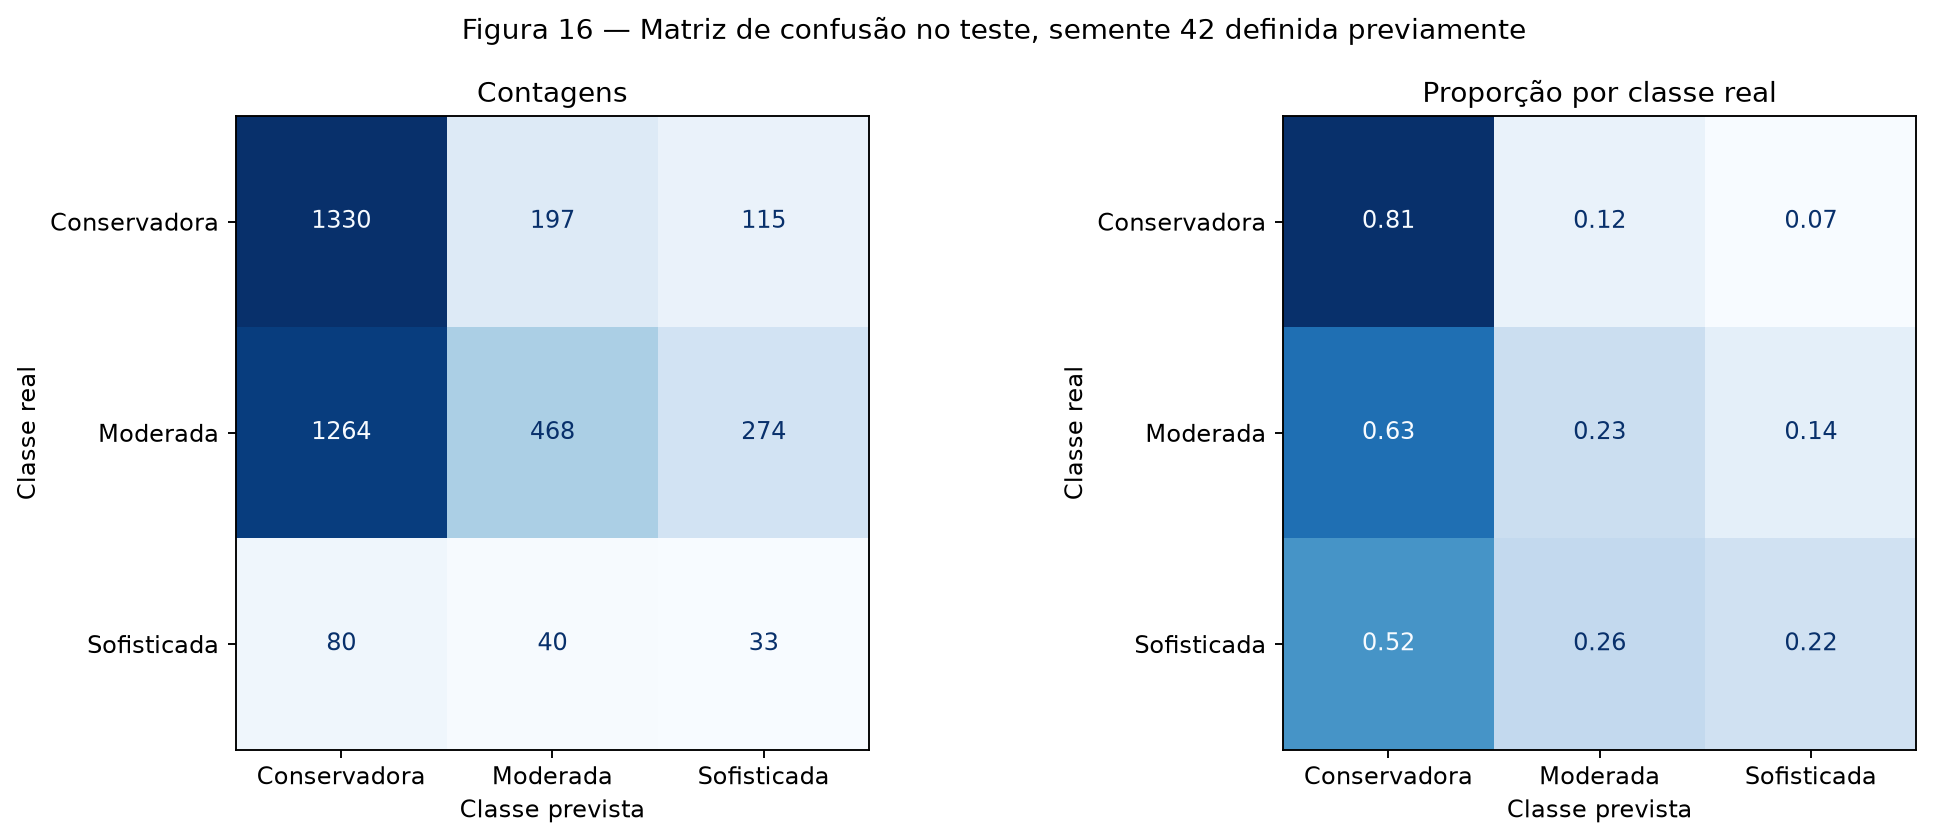

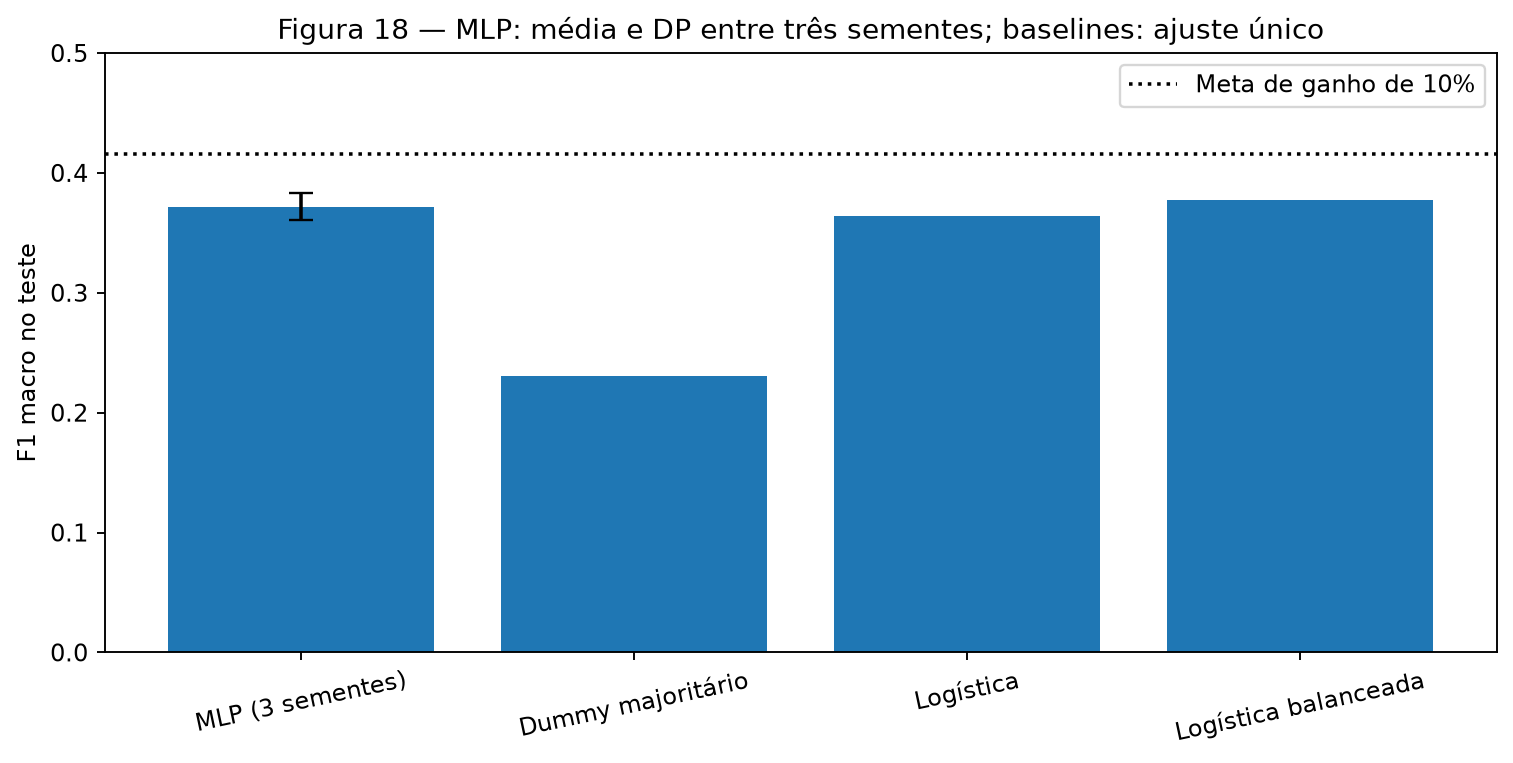

In [ ]:
display(Image(filename=str(pasta_classificacao / "figures" / "fig16-confusao-teste.png")))
display(Image(filename=str(pasta_classificacao / "figures" / "fig18-comparacao-teste.png")))


### 6.3. Continuidade da análise

A análise por subgrupo e a conclusão do protocolo A permanecem acima.
Ainda faltam a análise de subgrupos do protocolo B, os piores exemplos com hipóteses,
a importância por permutação comparada ao EDA e a síntese conjunta final.
Essas pendências também estão registradas no [relatório](index.md).